# PS, MS, and DA score comparison


This notebook loads evaluation scores from CSV files and compares per-species (PS), mixed-species (MS), and domain-adaptive (DA) models across six performance-evaluation regions.

Outputs include summary tables, overall-performance bar charts, and per-class heatmaps. Accuracy and per-class Dice are reported in the manuscript. IoU scores are included for exploratory comparison but are not reported in the manuscript.

In [1]:
from collections import OrderedDict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path('/home/nodokaizm/code')
PS_ROOT = PROJECT_ROOT / 'mrcnn_by_sp' / 'inference_results_recheck20261011' # <== Specify the directory where the PS model’s scores are saved
MS_ROOT = PROJECT_ROOT / 'au_travail_20250325' / 'inference_results_recheck20261011' # <== MS model's scores
DA_ROOT = PROJECT_ROOT / 'mrcnn_multi_domain' / 'inference_results_recheck20261011' # <== DA model's scores
OUTPUT_DIR = PROJECT_ROOT / 'mrcnn_multi_domain' / 'plots_dfs_recheck20261011' / 'score_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
mpl.rcParams['pdf.fonttype'] = 42

species_to_image = OrderedDict([
    ('acapod', 'acapod2_01_img.png'),
    ('alllit', 'alllit2_01_img.png'),
    ('burspi', 'burspi1_01_img.png'),
    ('euclon', 'euclon1_01_img.png'),
    ('exostr', 'exostr8_01_img.png'),
    ('hakdac', 'hakdac2_01_img.png'),
])
species_labels = OrderedDict([
    ('acapod', 'Acacia'), ('alllit', 'Allocasuarina'),
    ('burspi', 'Bursaria'), ('euclon', 'Eucalyptus'),
    ('exostr', 'Exocarpos'), ('hakdac', 'Hakea'),
])

def ps_score_path(image_size, image_name, thin):
    prefix = f'{image_size}_thin' if thin else str(image_size)
    return (PS_ROOT / f'{prefix}_singlespecies_700_epoch' / 'scores' /
            image_name.replace('.png', '_evaluation_scores.csv'))

def ms_score_path(image_size, thin):
    prefix = f'{image_size}_thin' if thin else str(image_size)
    return MS_ROOT / f'{prefix}_multispecies_700_epoch.tar' / 'scores' / 'evaluation_scores.csv'

def da_score_path(image_size, thin):
    # New DA run tags: original uses 256/512; thin uses 256thin/512thin.
    prefix = f'{image_size}thin' if thin else str(image_size)
    return DA_ROOT / f'{prefix}_multispecies_DA_lambda0p1_rerun' / 'scores' / 'evaluation_scores.csv'

models_thin = OrderedDict([
    ('PS-256 thin', lambda sp, img: ps_score_path(256, img, thin=True)),
    ('PS-512 thin', lambda sp, img: ps_score_path(512, img, thin=True)),
    ('MS-256 thin', lambda sp, img: ms_score_path(256, thin=True)),
    ('MS-512 thin', lambda sp, img: ms_score_path(512, thin=True)),
    ('DA-256 thin', lambda sp, img: da_score_path(256, thin=True)),
    ('DA-512 thin', lambda sp, img: da_score_path(512, thin=True)),
])

models_all = OrderedDict([
    ('PS-256', lambda sp, img: ps_score_path(256, img, thin=False)),
    ('PS-256 thin', lambda sp, img: ps_score_path(256, img, thin=True)),
    ('PS-512', lambda sp, img: ps_score_path(512, img, thin=False)),
    ('PS-512 thin', lambda sp, img: ps_score_path(512, img, thin=True)),
    ('MS-256', lambda sp, img: ms_score_path(256, thin=False)),
    ('MS-256 thin', lambda sp, img: ms_score_path(256, thin=True)),
    ('MS-512', lambda sp, img: ms_score_path(512, thin=False)),
    ('MS-512 thin', lambda sp, img: ms_score_path(512, thin=True)),
    ('DA-256', lambda sp, img: da_score_path(256, thin=False)),
    ('DA-256 thin', lambda sp, img: da_score_path(256, thin=True)),
    ('DA-512', lambda sp, img: da_score_path(512, thin=False)),
    ('DA-512 thin', lambda sp, img: da_score_path(512, thin=True)),
])

COLORS_THIN = ['lightcoral', 'firebrick', 'lightskyblue', 'steelblue', 'khaki', 'goldenrod']
COLORS_ALL = [
    '#fcbba1', '#cb181d', '#fb6a4a', '#99000d',
    '#bdd7e7', '#2171b5', '#6baed6', '#084594',
    '#fff7bc', '#fec44f', '#d9f0a3', '#78c679',
]
print('Output directory:', OUTPUT_DIR)


Output directory: /home/nodokaizm/code/mrcnn_multi_domain/plots_dfs_recheck20261011/score_comparison


In [2]:
def normalise_filename(value):
    return Path(str(value)).stem

def select_score_row(scores, image_name, model_label, path):
    if 'filename' not in scores.columns:
        if len(scores) != 1:
            raise ValueError(f'{model_label}: expected one row in {path}, found {len(scores)}')
        return scores.iloc[0]

    target = normalise_filename(image_name)
    selected = scores[scores['filename'].map(normalise_filename) == target]
    if len(selected) != 1:
        raise ValueError(f'{model_label}: expected one row for {target} in {path}, found {len(selected)}')
    return selected.iloc[0]

def load_scores(model_set):
    records, missing, cache = [], [], {}
    for species, image_name in species_to_image.items():
        for model_label, path_function in model_set.items():
            path = Path(path_function(species, image_name))
            if not path.is_file():
                missing.append(str(path))
                continue
            if path not in cache:
                cache[path] = pd.read_csv(path)
            row = select_score_row(cache[path], image_name, model_label, path).to_dict()
            records.append({'species': species, 'species_label': species_labels[species],
                            'image_name': image_name, 'model': model_label,
                            'score_file': str(path), **row})
    if missing:
        raise FileNotFoundError('Missing score file(s):\n' + '\n'.join(sorted(set(missing))))
    expected_rows = len(species_to_image) * len(model_set)
    df = pd.DataFrame(records)
    assert len(df) == expected_rows, f'Expected {expected_rows} rows, obtained {len(df)}'
    return df

def metric_table(df, model_set, metric_name):
    table = (df.pivot(index='species', columns='model', values=metric_name)
             .reindex(index=species_to_image.keys(), columns=model_set.keys()))
    table.index = [species_labels[species] for species in table.index]
    table.index.name = 'Species'
    return table


,species_label,model,mean_dice,mean_iou,accuracy
0,Acacia,PS-256 thin,0.604230,0.514986,0.675105
1,Acacia,PS-512 thin,0.574859,0.483693,0.647543
2,Acacia,MS-256 thin,0.751588,0.612223,0.661294
3,Acacia,MS-512 thin,0.734606,0.600075,0.678531
4,Acacia,DA-256 thin,0.747180,0.602731,0.685834
5,Acacia,DA-512 thin,0.631298,0.504729,0.571601
6,Allocasuarina,PS-256 thin,0.832276,0.717569,0.781772
7,Allocasuarina,PS-512 thin,0.837170,0.722375,0.775656
8,Allocasuarina,MS-256 thin,0.821389,0.704010,0.781652
9,Allocasuarina,MS-512 thin,0.854179,0.747755,0.796258


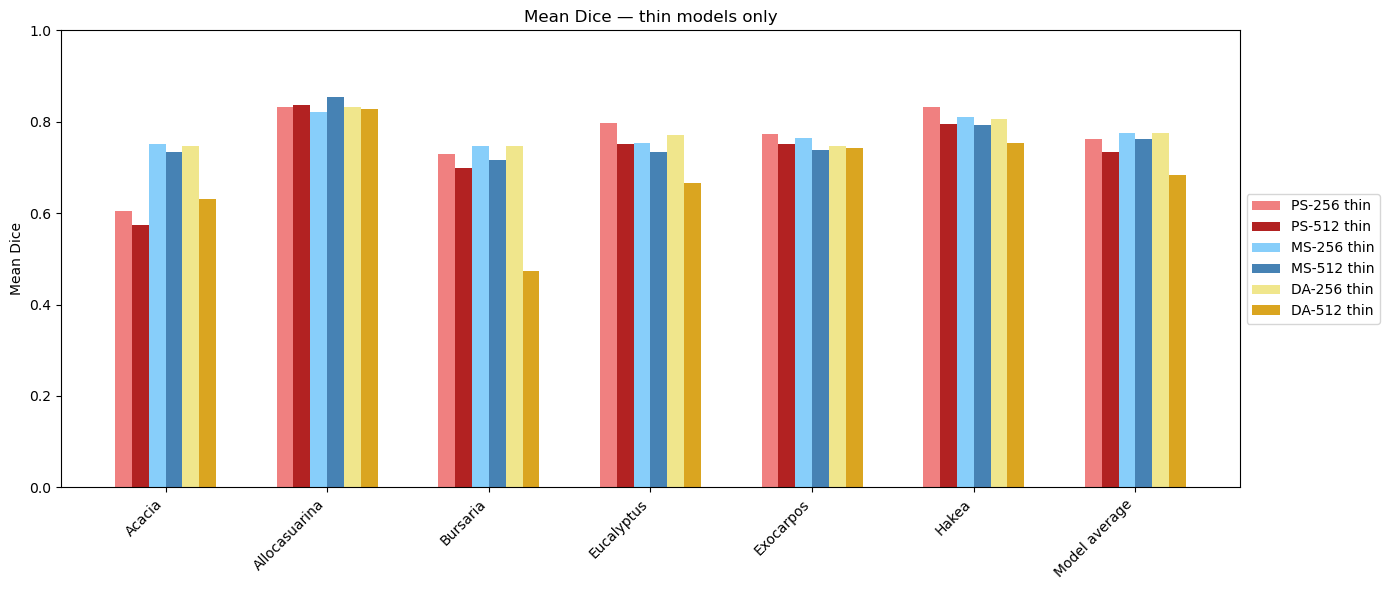

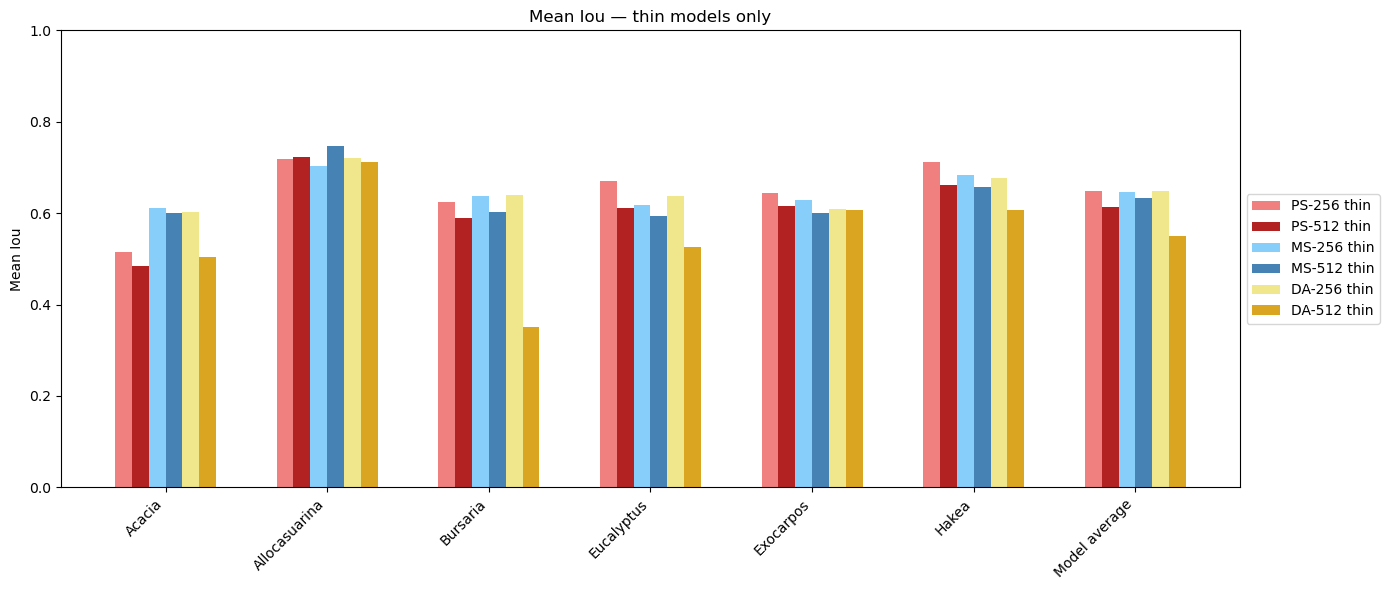

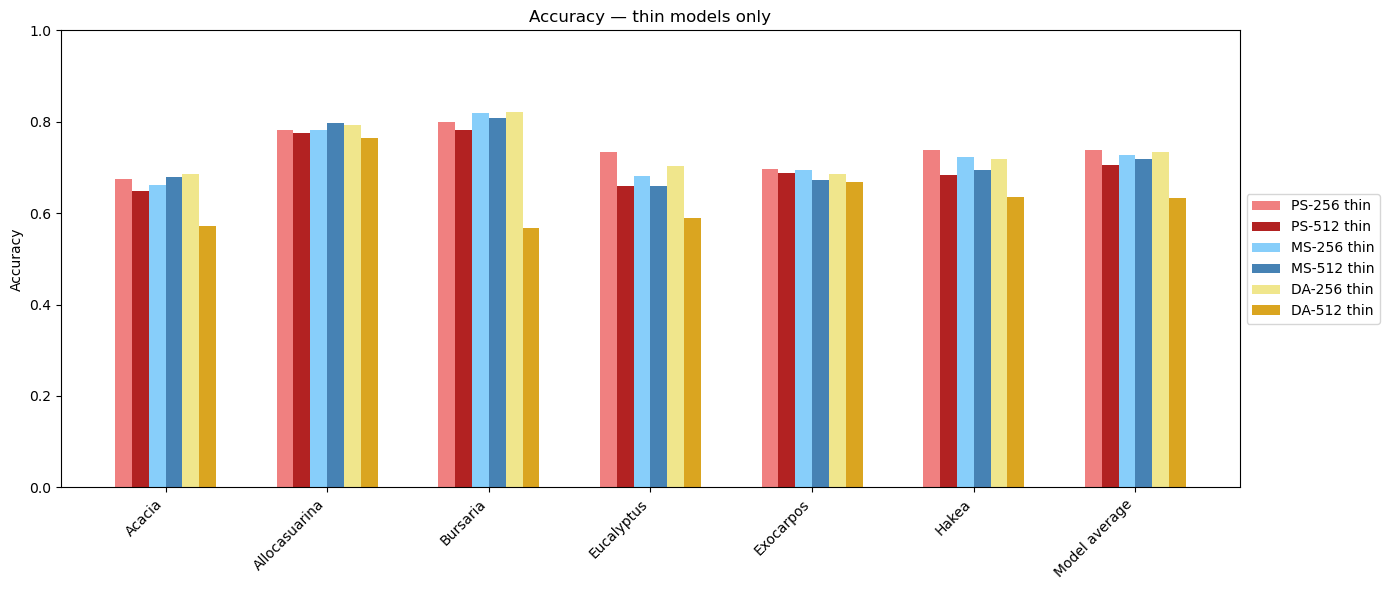

In [3]:
# Six thin-model figures
df_thin = load_scores(models_thin)
df_thin.to_csv(OUTPUT_DIR / 'all_thin_model_scores.csv', index=False)
display(df_thin[['species_label', 'model', 'mean_dice', 'mean_iou', 'accuracy']])

def plot_overall_metric(df, model_set, colors, metric_name, filename_stem, title):
    table = metric_table(df, model_set, metric_name)
    table = pd.concat([table, pd.DataFrame([table.mean(axis=0)], index=['Model average'])])
    table.to_csv(OUTPUT_DIR / f'{filename_stem}.csv')

    n_models = len(model_set)
    x = np.arange(len(table.index)) * 1.15
    width = min(.72 / n_models, .12)
    offsets = (np.arange(n_models) - (n_models - 1) / 2) * width
    fig, ax = plt.subplots(figsize=(14, 6))
    for i, (label, color) in enumerate(zip(model_set.keys(), colors)):
        ax.bar(x + offsets[i], table[label], width, color=color, label=label)
    ax.set_xticks(x)
    ax.set_xticklabels(table.index, rotation=45, ha='right')
    ax.set_ylim(0, 1)
    ax.set_ylabel(metric_name.replace('_', ' ').title())
    ax.set_title(title)
    ax.legend(loc='center left', bbox_to_anchor=(1.0, .5))
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{filename_stem}.pdf', bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / f'{filename_stem}.png', dpi=300, bbox_inches='tight')
    plt.show()

for metric in ['mean_dice', 'mean_iou', 'accuracy']:
    plot_overall_metric(
        df_thin, models_thin, COLORS_THIN, metric,
        f'{metric}_thin_models',
        f"{metric.replace('_', ' ').title()} — thin models only"
    )


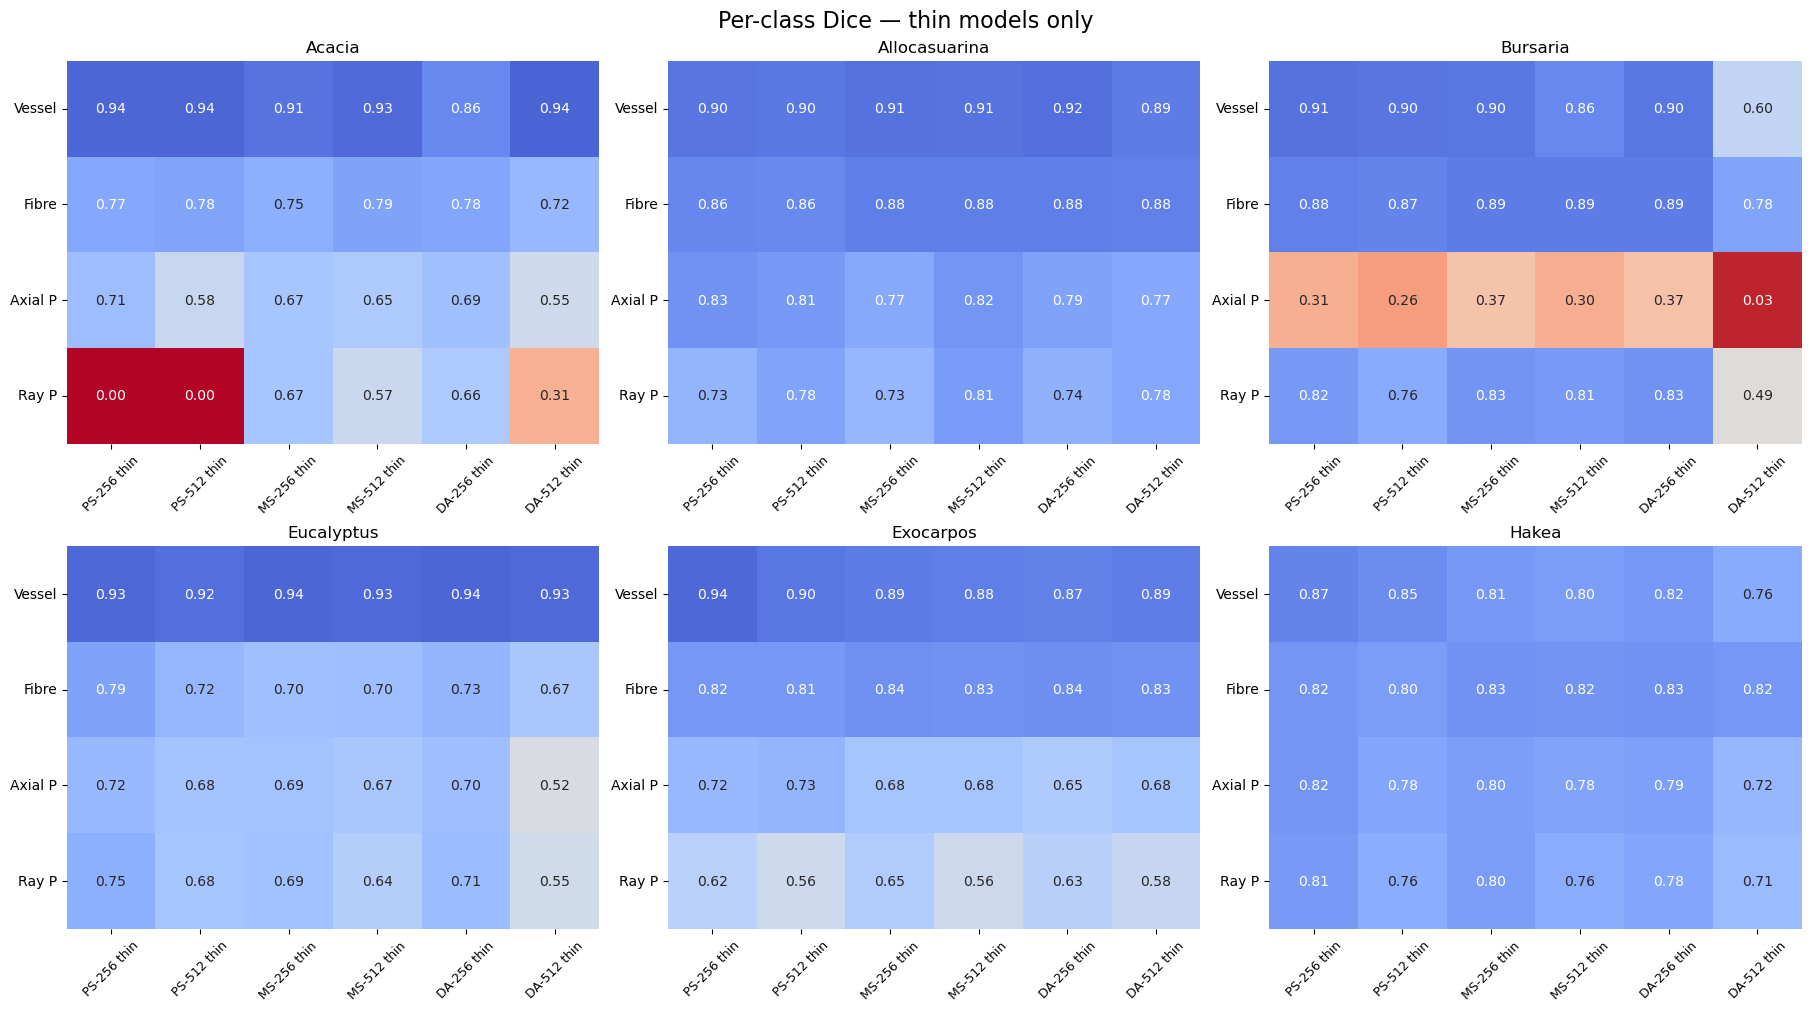

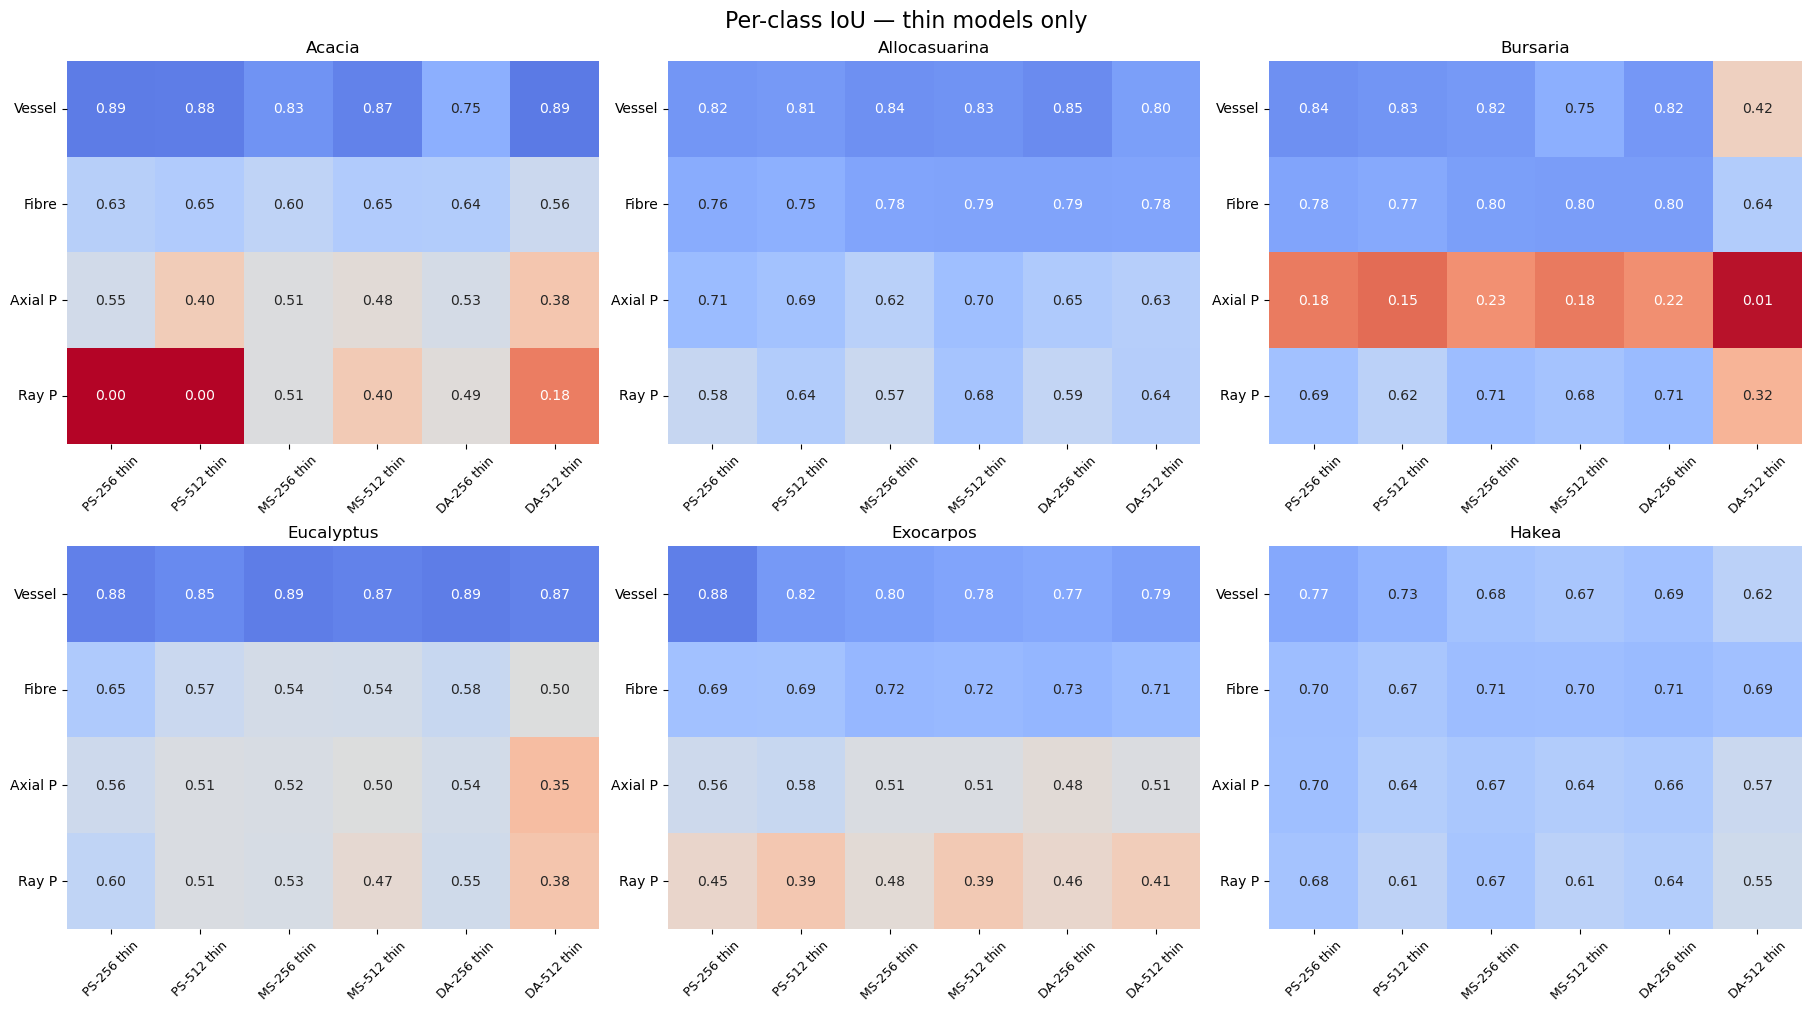

In [4]:
CLASS_ORDER = ['vessel', 'fiber', 'parenchyma', 'ray']
CLASS_LABELS = {'vessel': 'Vessel', 'fiber': 'Fibre', 'parenchyma': 'Axial P', 'ray': 'Ray P'}

def plot_per_class_heatmaps(df, model_set, score_type, filename_stem, title):
    columns = [f'{cell_class}_{score_type}' for cell_class in CLASS_ORDER]
    missing_columns = [column for column in columns if column not in df.columns]
    if missing_columns:
        raise KeyError(f'Missing class-score columns: {missing_columns}')

    fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
    for axis, species in zip(axes.flat, species_to_image):
        values = (df[df['species'] == species].set_index('model')
                  .reindex(model_set.keys())[columns].T)
        values.index = [CLASS_LABELS[cell_class] for cell_class in CLASS_ORDER]
        sns.heatmap(values, annot=True, fmt='.2f', cmap='coolwarm_r', vmin=0, vmax=1,
                    cbar=False, ax=axis)
        axis.set_title(species_labels[species])
        axis.set_xlabel('')
        axis.set_ylabel('')
        axis.tick_params(axis='x', rotation=45, labelsize=9)
        axis.tick_params(axis='y', rotation=0)
    fig.suptitle(title, fontsize=16)
    fig.savefig(OUTPUT_DIR / f'{filename_stem}.pdf', bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / f'{filename_stem}.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_per_class_heatmaps(df_thin, models_thin, 'dice', 'per_class_dice_thin_models',
                         'Per-class Dice — thin models only')
plot_per_class_heatmaps(df_thin, models_thin, 'iou', 'per_class_iou_thin_models',
                         'Per-class IoU — thin models only')
